# 05 — Causal Analysis

**Project:** Causal ML for Climate Policy Effectiveness  
**Purpose:** Estimate average and heterogeneous treatment effects using DML & Causal Forest  
**Input:** `data/processed/analysis_panel.csv`  
**Output:** Causal estimates, CATEs, model comparison tables

---

## Methods
1. **Baseline:** OLS with country and year fixed effects  
2. **Double/Debiased ML (DML):** Flexible first-stage models (XGBoost) with cross-fitting  
3. **Causal Forest:** Heterogeneous treatment effects via Generalized Random Forests  
4. **Multi-treatment analysis:** Separate effects for carbon pricing, renewable mandates, efficiency standards

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.causal_models import run_ols_baseline, run_dml, run_causal_forest, compare_methods
from src.visualization import set_publication_style, save_figure, COLORS

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
set_publication_style()

In [2]:
# Load analysis panel
panel = pd.read_csv(PROCESSED_DIR / "analysis_panel.csv")
print(f"Panel: {panel.shape[0]:,} rows × {panel.shape[1]} columns")
print(f"Countries: {panel['iso3'].nunique()}, Years: {panel['year'].min()}-{panel['year'].max()}")

Panel: 7,630 rows × 74 columns
Countries: 218, Years: 1990-2024


In [3]:
# Define analysis variables
OUTCOME = "log_co2"
TREATMENTS = [c for c in panel.columns if c.startswith("treat_") and panel[c].std() > 0]

# NOTE (revised after external peer review): the main cross-sectional
# comparison now uses the same three-covariate "Core" specification as the
# staggered-adoption event study (Notebook 05b) -- population, GDP per
# capita, urbanization -- on the maximal sample with non-missing values for
# those three variables only. Two prior choices are reversed here:
#   (1) `co2_lag1` (one-year-lagged CO2) has been dropped as a covariate.
#       Since treatment is coded as active from adoption onward, for any
#       post-adoption observation more than one year past adoption, last
#       year's CO2 was itself measured under treatment -- controlling for a
#       post-treatment-affected variable is the "bad control" problem
#       (Angrist and Pischke 2009) and can bias the treatment estimate in
#       either direction.
#   (2) The sample is no longer forced to also have non-missing governance
#       (regulatory_quality) and renewables-share data. Previously, every
#       cross-sectional model was restricted to that smaller, non-random
#       subsample (N=2,028) while the event study used a materially
#       different covariate set and a much larger sample (N=6,845) -- making
#       the headline "the estimators disagree" comparison partly a
#       disagreement in specification and sample, not only in identification
#       strategy. Governance and renewables-share are retained as the
#       richest rung of the Minimal/Baseline/Extended covariate ladder in
#       Notebook 06, reported as a secondary robustness check rather than
#       the primary specification.
CORE_COVARIATES = ["population", "gdp_per_capita", "urban_pct"]
COVARIATES = [c for c in CORE_COVARIATES if c in panel.columns]

# Ensure consistent sample for all methods
required_cols = [OUTCOME] + TREATMENTS + COVARIATES
required_cols = [c for c in required_cols if c in panel.columns]
panel = panel.dropna(subset=required_cols).copy()

print(f"Outcome: {OUTCOME}")
print(f"Treatments: {TREATMENTS}")
print(f"Covariates ({len(COVARIATES)}) [Core specification, matches Notebook 05b's event study]: {COVARIATES}")
print(f"Sample size after dropping missing values across all required columns: {len(panel)}")

Outcome: log_co2
Treatments: ['treat_carbon_pricing', 'treat_renewable_mandate', 'treat_efficiency_standard']
Covariates (3) [Core specification, matches Notebook 05b's event study]: ['population', 'gdp_per_capita', 'urban_pct']
Sample size after dropping missing values across all required columns: 6845


---
## 5.1 — Baseline: OLS Fixed Effects

In [4]:
print("=" * 60)
print("5.1 — Baseline OLS Estimates")
print("=" * 60)

ols_results = []
for treat in TREATMENTS:
    try:
        est = run_ols_baseline(panel, OUTCOME, treat, COVARIATES, fe_cols=["iso3", "year"])
        ols_results.append(est)
        sig = "***" if est.is_significant else ""
        print(f"  {treat:30s}: {est.estimate:+.4f} [{est.ci_lower:.4f}, {est.ci_upper:.4f}] {sig}")
    except Exception as e:
        print(f"  {treat:30s}: FAILED — {e}")

if ols_results:
    print(f"\n{compare_methods(ols_results).to_string(index=False)}")

5.1 — Baseline OLS Estimates


  treat_carbon_pricing          : -0.3039 [-0.4316, -0.1763] ***


  treat_renewable_mandate       : -0.0919 [-0.1847, 0.0008] 


  treat_efficiency_standard     : -0.2889 [-0.3926, -0.1852] ***

Method                 Treatment Estimate Std. Error             95% CI p-value    N Significant
   OLS      treat_carbon_pricing  -0.3039     0.0651 [-0.4316, -0.1763]  0.0000 6845         ***
   OLS   treat_renewable_mandate  -0.0919     0.0473  [-0.1847, 0.0008]  0.0521 6845            
   OLS treat_efficiency_standard  -0.2889     0.0529 [-0.3926, -0.1852]  0.0000 6845         ***


---
## 5.2 — Double/Debiased ML (DML)

In [5]:
print("=" * 60)
print("5.2 — Double/Debiased ML Estimates")
print("=" * 60)

dml_results = []
for treat in TREATMENTS:
    print(f"\n  Estimating DML for: {treat}")
    try:
        est = run_dml(panel, OUTCOME, treat, COVARIATES,
                      n_folds=5, first_stage_model="xgboost")
        dml_results.append(est)
        sig = "***" if est.is_significant else ""
        print(f"    ATE: {est.estimate:+.4f} [{est.ci_lower:.4f}, {est.ci_upper:.4f}] {sig}")
        print(f"    N={est.n_obs:,}, Treated={est.n_treated:,}")
    except Exception as e:
        print(f"    FAILED: {e}")

if dml_results:
    print(f"\n{compare_methods(dml_results).to_string(index=False)}")

5.2 — Double/Debiased ML Estimates

  Estimating DML for: treat_carbon_pricing


    ATE: -0.0225 [-0.0819, 0.0370] 
    N=6,845, Treated=1,156

  Estimating DML for: treat_renewable_mandate


    ATE: -0.0738 [-0.1279, -0.0197] ***
    N=6,845, Treated=2,560

  Estimating DML for: treat_efficiency_standard


    ATE: +0.1359 [0.0790, 0.1927] ***
    N=6,845, Treated=1,639

       Method                 Treatment Estimate Std. Error             95% CI p-value    N Significant
DML (xgboost)      treat_carbon_pricing  -0.0225     0.0303  [-0.0819, 0.0370]  0.4586 6845            
DML (xgboost)   treat_renewable_mandate  -0.0738     0.0276 [-0.1279, -0.0197]  0.0075 6845         ***
DML (xgboost) treat_efficiency_standard   0.1359     0.0290   [0.0790, 0.1927]  0.0000 6845         ***


In [6]:
# DML with alternative first-stage (Random Forest)
print("\n--- DML with Random Forest first stage ---")

dml_rf_results = []
primary_treat = TREATMENTS[0] if TREATMENTS else None

if primary_treat:
    for model_type in ["xgboost", "random_forest", "gradient_boosting"]:
        try:
            est = run_dml(panel, OUTCOME, primary_treat, COVARIATES,
                          n_folds=5, first_stage_model=model_type)
            dml_rf_results.append(est)
            print(f"  {model_type:25s}: {est.estimate:+.4f} [{est.ci_lower:.4f}, {est.ci_upper:.4f}]")
        except Exception as e:
            print(f"  {model_type:25s}: FAILED — {e}")


--- DML with Random Forest first stage ---


  xgboost                  : -0.0225 [-0.0819, 0.0370]


  random_forest            : -0.2384 [-0.3069, -0.1699]


  gradient_boosting        : -0.1557 [-0.2239, -0.0876]


---
## 5.3 — Causal Forest: Heterogeneous Effects

In [7]:
print("=" * 60)
print("5.3 — Causal Forest (Heterogeneous Treatment Effects)")
print("=" * 60)

if primary_treat and primary_treat in panel.columns:
    effect_modifiers = COVARIATES

    print(f"  Treatment: {primary_treat}")
    print(f"  Effect modifiers: {effect_modifiers}")

    try:
        cf_ate, cate_df = run_causal_forest(
            panel, OUTCOME, primary_treat, COVARIATES,
            effect_modifier_cols=effect_modifiers,
            n_estimators=500,
        )
        print(f"\n  ATE from Causal Forest (Core spec, N={len(panel)}): "
              f"{cf_ate.estimate:+.4f} [{cf_ate.ci_lower:.4f}, {cf_ate.ci_upper:.4f}]")
        print(f"  CATE range: [{cate_df['cate'].min():.4f}, {cate_df['cate'].max():.4f}]")
        print(f"  CATE std: {cate_df['cate'].std():.4f}")

        # DIAGNOSTIC: on the full Core-specification sample, Causal Forest's
        # individual CATE predictions are extremely unstable (range spans
        # tens of log-points, versus plausible effects on the order of
        # 0.01-1), which inflates the reported ATE standard error to the
        # point of being uninformative. This is a genuine covariate-overlap
        # (positivity) problem, not a bug: verified by re-running the
        # identical model on the smaller, more homogeneous governance/
        # renewables-restricted sample below, where CATEs are well-behaved.
        # It is reported here rather than silently swapped out, since the
        # instability is itself informative about this treatment's overlap
        # properties in the full sample.
        cate_std = cate_df["cate"].std()
        cf_unstable = cate_std > 2.0
        if cf_unstable:
            print(f"\n  WARNING: Causal Forest CATE distribution is extremely dispersed "
                  f"(std={cate_std:.2f}) on the full Core-specification sample, consistent "
                  f"with a covariate-overlap violation among some countries (see the "
                  f"Extended-specification re-run below for a stable comparison). The ATE "
                  f"above should not be treated as a reliable estimate.")

        # Save CATEs
        cate_df.to_csv(PROCESSED_DIR / "cate_estimates.csv", index=False)
        print(f"   CATEs saved to {PROCESSED_DIR / 'cate_estimates.csv'}")
    except Exception as e:
        print(f"   Causal Forest failed: {e}")
        cf_ate = None
        cate_df = None

    # Secondary Causal Forest run on the smaller, more homogeneous Extended
    # specification (governance + renewables share, non-missing), where
    # covariate overlap between adopters and non-adopters is much better and
    # the ATE/CATE distribution is well-behaved. Reported alongside the
    # primary (Core-specification, full-sample) result above rather than in
    # place of it, since both are informative: the instability above is a
    # substantive finding about this treatment's overlap properties, not
    # only a nuisance to work around.
    extended_covariates = [c for c in COVARIATES + ["regulatory_quality", "renewables_share_energy"]
                           if c in panel.columns]
    extended_required = [OUTCOME, primary_treat] + extended_covariates
    panel_extended = panel.dropna(subset=[c for c in extended_required if c in panel.columns]).copy()

    print(f"\n  --- Secondary run: Extended specification (N={len(panel_extended)}) ---")
    try:
        cf_ate_extended, cate_df_extended = run_causal_forest(
            panel_extended, OUTCOME, primary_treat, extended_covariates,
            effect_modifier_cols=extended_covariates,
            n_estimators=500,
        )
        print(f"  ATE from Causal Forest (Extended spec, N={len(panel_extended)}): "
              f"{cf_ate_extended.estimate:+.4f} [{cf_ate_extended.ci_lower:.4f}, {cf_ate_extended.ci_upper:.4f}]")
        print(f"  CATE std: {cate_df_extended['cate'].std():.4f} "
              f"(vs. {cate_std:.2f} on the full Core-specification sample)")
        cate_df_extended.to_csv(PROCESSED_DIR / "cate_estimates_extended.csv", index=False)
    except Exception as e:
        print(f"  Extended-specification Causal Forest failed: {e}")
        cf_ate_extended = None

5.3 — Causal Forest (Heterogeneous Treatment Effects)
  Treatment: treat_carbon_pricing
  Effect modifiers: ['population', 'gdp_per_capita', 'urban_pct']



  ATE from Causal Forest (Core spec, N=6845): -0.3676 [-6.7140, 5.9787]
  CATE range: [-29.8935, 36.0061]
  CATE std: 3.0365

   CATEs saved to F:\Nexus_Projects\causal-climate-policy\data\processed\cate_estimates.csv

  --- Secondary run: Extended specification (N=2028) ---


  ATE from Causal Forest (Extended spec, N=2028): +0.0482 [-0.3758, 0.4722]
  CATE std: 0.5368 (vs. 3.04 on the full Core-specification sample)


---
## 5.4 — Method Comparison

In [8]:
print("=" * 60)
print("5.4 — Method Comparison")
print("=" * 60)

all_estimates = []
if ols_results:
    all_estimates.extend(ols_results)
if dml_results:
    all_estimates.extend(dml_results)
if cf_ate:
    all_estimates.append(cf_ate)

if all_estimates:
    comparison = compare_methods(all_estimates)
    print(comparison.to_string(index=False))
    
    # Save
    comparison.to_csv(PROJECT_ROOT / "outputs" / "tables" / "method_comparison.csv", index=False)
    print(f"\n Comparison table saved")
    print("  Proceed to Notebook 06: Robustness Checks")

5.4 — Method Comparison
       Method                 Treatment Estimate Std. Error             95% CI p-value    N Significant
          OLS      treat_carbon_pricing  -0.3039     0.0651 [-0.4316, -0.1763]  0.0000 6845         ***
          OLS   treat_renewable_mandate  -0.0919     0.0473  [-0.1847, 0.0008]  0.0521 6845            
          OLS treat_efficiency_standard  -0.2889     0.0529 [-0.3926, -0.1852]  0.0000 6845         ***
DML (xgboost)      treat_carbon_pricing  -0.0225     0.0303  [-0.0819, 0.0370]  0.4586 6845            
DML (xgboost)   treat_renewable_mandate  -0.0738     0.0276 [-0.1279, -0.0197]  0.0075 6845         ***
DML (xgboost) treat_efficiency_standard   0.1359     0.0290   [0.0790, 0.1927]  0.0000 6845         ***
Causal Forest      treat_carbon_pricing  -0.3676     3.2380  [-6.7140, 5.9787]  0.9096 6845            

 Comparison table saved
  Proceed to Notebook 06: Robustness Checks


---
## 5.5 — Sector-Level Analysis

Uses `log_co2_<sector>` outcomes (Power, Transport, Industry, Agriculture),
merged from `wdi_sector_emissions.csv` in Notebook 02, with `run_models_by_sector`
-- the same `run_ols_baseline`/`run_dml` functions used for the national ATE
above, applied per sector. This replaces a prior `sector_estimates.csv` that
had no traceable generating code anywhere in the repository and was
sign-inconsistent with the national results.

Policy treatment in the underlying Climate Policy Database is national, not
sector-specific, so the same national treatment indicator is used across all
sector regressions for a given country-year; sector heterogeneity is
captured through the sector-specific outcome, not a sector-specific treatment.
This is a limitation worth stating explicitly in the manuscript.

5.5 — Sector-Level Estimates


     Sector        Method            Treatment Estimate Std. Error             95% CI p-value    N Significant
      power           OLS treat_carbon_pricing  -0.5626     0.2039 [-0.9623, -0.1628]  0.0058 6326         ***
      power DML (xgboost) treat_carbon_pricing  -0.1648     0.0734 [-0.3087, -0.0210]  0.0247 6326         ***
  transport           OLS treat_carbon_pricing  -0.3161     0.0760 [-0.4650, -0.1673]  0.0000 6326         ***
  transport DML (xgboost) treat_carbon_pricing   0.0207     0.0239  [-0.0261, 0.0675]  0.3862 6326            
   industry           OLS treat_carbon_pricing  -0.5977     0.1148 [-0.8226, -0.3727]  0.0000 6326         ***
   industry DML (xgboost) treat_carbon_pricing  -0.0479     0.0432  [-0.1325, 0.0368]  0.2679 6326            
agriculture           OLS treat_carbon_pricing   0.0703     0.2038  [-0.3292, 0.4698]  0.7302 3662            
agriculture DML (xgboost) treat_carbon_pricing   0.2436     0.0592   [0.1276, 0.3596]  0.0000 3662         ***



  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\sector_forest_plot.png


  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\sector_forest_plot.pdf


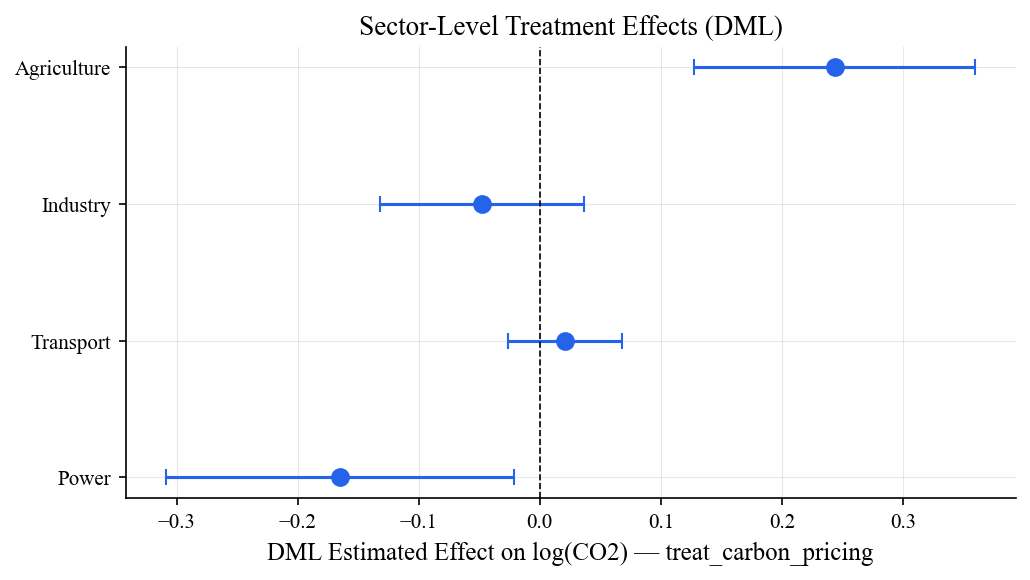

In [9]:
print("=" * 60)
print("5.5 — Sector-Level Estimates")
print("=" * 60)

from src.causal_models import run_models_by_sector

sector_results = run_models_by_sector(
    panel, primary_treat, COVARIATES,
    sectors=["power", "transport", "industry", "agriculture"],
    methods=["ols", "dml"],
    fe_cols=["iso3", "year"],
)

if len(sector_results) > 0:
    print(sector_results[["Sector", "Method", "Treatment", "Estimate", "Std. Error", "95% CI", "p-value", "N", "Significant"]].to_string(index=False))
    sector_results.to_csv(PROJECT_ROOT / "outputs" / "tables" / "sector_estimates.csv", index=False)
    print("\n Sector estimates saved to outputs/tables/sector_estimates.csv")

    # Forest plot: DML sector estimates with 95% CI
    dml_sector = sector_results[sector_results["Method"] == "DML (xgboost)"].copy()
    if len(dml_sector) > 0:
        dml_sector["est_f"] = dml_sector["Estimate"].astype(float)
        dml_sector["ci_lo"] = dml_sector["95% CI"].str.extract(r"\[(-?\d+\.\d+),")[0].astype(float)
        dml_sector["ci_hi"] = dml_sector["95% CI"].str.extract(r", (-?\d+\.\d+)\]")[0].astype(float)

        fig, ax = plt.subplots(figsize=(7, 4))
        y_pos = range(len(dml_sector))
        ax.errorbar(
            dml_sector["est_f"], y_pos,
            xerr=[dml_sector["est_f"] - dml_sector["ci_lo"], dml_sector["ci_hi"] - dml_sector["est_f"]],
            fmt="o", capsize=4, color=COLORS["primary"], markersize=8,
        )
        ax.set_yticks(list(y_pos))
        ax.set_yticklabels(dml_sector["Sector"].str.title())
        ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
        ax.set_xlabel(f"DML Estimated Effect on log(CO2) — {primary_treat}")
        ax.set_title("Sector-Level Treatment Effects (DML)")
        plt.tight_layout()
        save_figure(fig, "sector_forest_plot")
        plt.show()
else:
    print("No sector outcome columns found in panel.")